In [41]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_samples, silhouette_score
from matplotlib import cm
import sys
from pathlib import Path

In [42]:
# Add the project root (parent of notebooks/) to sys.path
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.pipeline import NYCTaxiPipeline

pipe = NYCTaxiPipeline()
train_df, test_df = pipe.split()

train_ready = pipe.fit_transform(train_df)
test_ready = pipe.transform(test_df)

In [43]:
# 1. Build the 263 Zones x 24 Hours Demand Profile Matrix
# We aggregate the training data to find the average trip count per zone for each hour of the day (0 to 23).
profile_df = (
    train_df.groupby(["zone_id", "hour"])["trip_count"]
    .mean()
    .unstack(level="hour")  # Shape: (263 zones, 24 hours)
    .fillna(0)
)

# Extract feature matrix X and zone IDs
zone_ids = profile_df.index.values
X_profiles = profile_df.values

# 2. Standardize the Demand Profiles
# This ensures that high-volume zones (like Midtown) and low-volume zones 
# are compared based on their temporal *shape* rather than absolute magnitude.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_profiles)

In [44]:
seed = 123

In [45]:
# 3. Evaluate K-Means Across Different Values of k Using Silhouette Score
k_range = range(3, 9)  # Testing k from 3 to 8
silhouette_scores = []
inertias = []

print("Evaluating K-Means cluster configurations...")
for k in k_range:
  kmeans = KMeans(n_clusters=k, random_state=seed, n_init=10)
  cluster_labels = kmeans.fit_predict(X_scaled)

  # Compute Silhouette Score (higher is better, measures cluster separation & cohesion)
  score = silhouette_score(X_scaled, cluster_labels)
  silhouette_scores.append(score)
  inertias.append(kmeans.inertia_)
  print(f" > k = {k} | Silhouette Score: {score:.4f}")

Evaluating K-Means cluster configurations...
 > k = 3 | Silhouette Score: 0.8088
 > k = 4 | Silhouette Score: 0.8022
 > k = 5 | Silhouette Score: 0.7945
 > k = 6 | Silhouette Score: 0.7971
 > k = 7 | Silhouette Score: 0.7799
 > k = 8 | Silhouette Score: 0.7449


In [46]:
# 4. Select Optimal k
# optimal_k = k_range[np.argmax(silhouette_scores)]
# print(
#     f"\n✨ Optimal k chosen by highest Silhouette Score: k = {optimal_k}"
# )

optimal_k = 6

# 5. Fit Final Optimal K-Means Model
optimal_kmeans = KMeans(n_clusters=optimal_k, random_state=seed, n_init=10)
final_labels = optimal_kmeans.fit_predict(X_scaled)

# Map cluster labels back to zones
zone_clusters = pd.DataFrame(
    {"zone_id": zone_ids, "cluster_id": final_labels}
).set_index("zone_id")

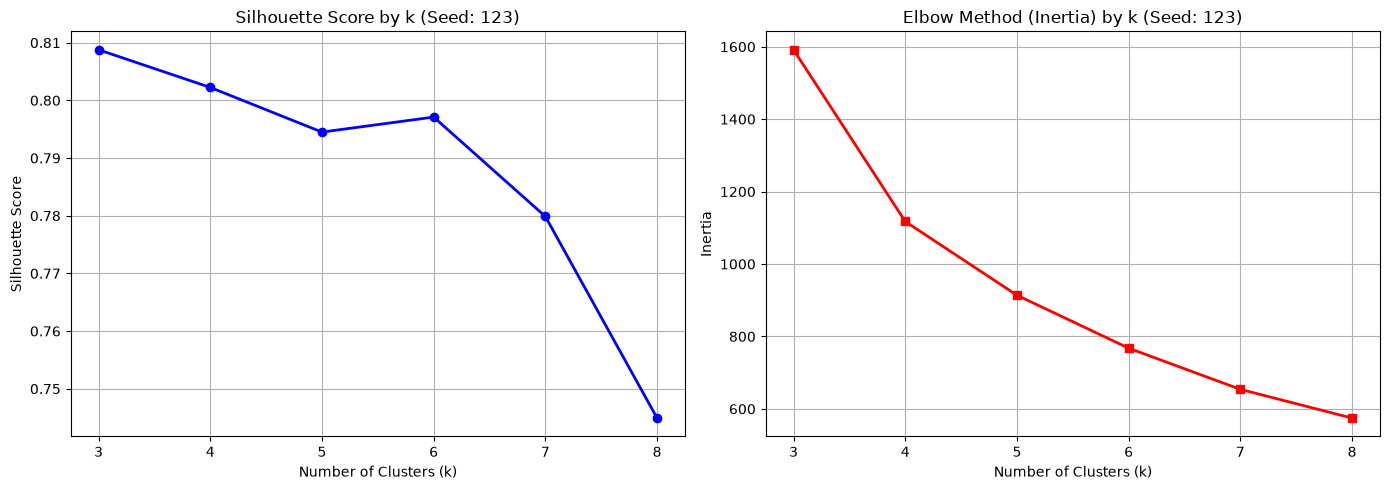

In [47]:
# Plot Silhouette Scores & Inertia Elbow
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, silhouette_scores, marker="o", color="b", lw=2)
axes[0].set_title(
    f"Silhouette Score by k (Seed: {seed})", fontsize=12
)
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Silhouette Score")
axes[0].grid(True)

axes[1].plot(k_range, inertias, marker="s", color="r", lw=2)
axes[1].set_title(
    f"Elbow Method (Inertia) by k (Seed: {seed})", fontsize=12
)
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Inertia")
axes[1].grid(True)

plt.tight_layout()

# Save the plot with the random seed in the filename
plt.savefig(
    f"../reports/figures/kmeans_silhouette_elbow_seed_{seed}.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

Explained variance by PCA components: [0.78826275 0.14320237]


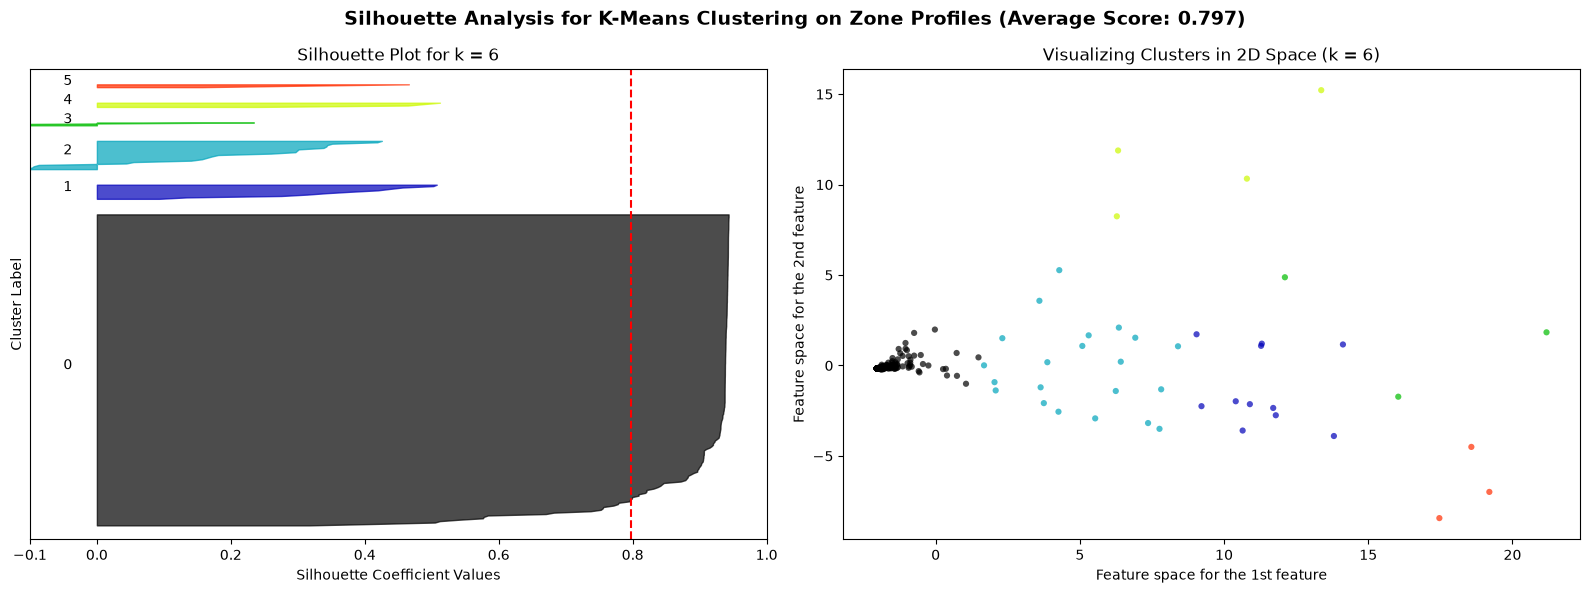

In [48]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# 1. Silhouette Plot (Left Subplot)
ax1.set_xlim([-0.1, 1.0])
# (n_clusters + 1)*10 gives space between silhouette plots for different clusters
ax1.set_ylim([0, len(X_scaled) + (optimal_k + 1) * 10])

kmeans = KMeans(
    n_clusters=optimal_k, random_state=seed, n_init=10
)
cluster_labels = kmeans.fit_predict(X_scaled)

# Calculate average silhouette score for the whole plot
silhouette_avg = silhouette_score(X_scaled, cluster_labels)
sample_silhouette_values = silhouette_samples(X_scaled, cluster_labels)

y_lower = 10
for i in range(optimal_k):
  # Aggregate silhouette scores for samples belonging to cluster i, and sort them
  ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
  ith_cluster_silhouette_values.sort()

  size_cluster_i = ith_cluster_silhouette_values.shape[0]
  y_upper = y_lower + size_cluster_i

  color = cm.nipy_spectral(float(i) / optimal_k)
  ax1.fill_betweenx(
      np.arange(y_lower, y_upper),
      0,
      ith_cluster_silhouette_values,
      facecolor=color,
      edgecolor=color,
      alpha=0.7,
  )

  # Label the silhouette plots with their cluster numbers at the middle
  ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

  # Compute new y_lower for next cluster plot
  y_lower = y_upper + 10  # 10 for the 0 samples

ax1.set_title(f"Silhouette Plot for k = {optimal_k}")
ax1.set_xlabel("Silhouette Coefficient Values")
ax1.set_ylabel("Cluster Label")

# The vertical line for average silhouette score of all the values
ax1.axvline(x=silhouette_avg, color="red", linestyle="--")
ax1.set_yticks([])  # Clear the y-axis labels / ticks
ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1.0])

# 2. PCA Scatter Plot (Right Subplot - for visual reference alongside the diagram)
pca = PCA(n_components=2, random_state=seed)
X_pca = pca.fit_transform(X_scaled)
print(f"Explained variance by PCA components: {pca.explained_variance_ratio_}")
colors = cm.nipy_spectral(cluster_labels.astype(float) / optimal_k)

ax2.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    marker=".",
    s=80,
    lw=0,
    alpha=0.7,
    c=colors,
    edgecolor="k",
)

# Plot cluster centers if needed, or keep clean
ax2.set_title(f"Visualizing Clusters in 2D Space (k = {optimal_k})")
ax2.set_xlabel("Feature space for the 1st feature")
ax2.set_ylabel("Feature space for the 2nd feature")

plt.suptitle(
    f"Silhouette Analysis for K-Means Clustering on Zone Profiles (Average Score:"
    f" {silhouette_avg:.3f})",
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()

# Save the plot with k and seed in the filename before showing it
plt.savefig(
    f"../reports/figures/kmeans_silhouette_analysis_k{optimal_k}_seed_{seed}.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

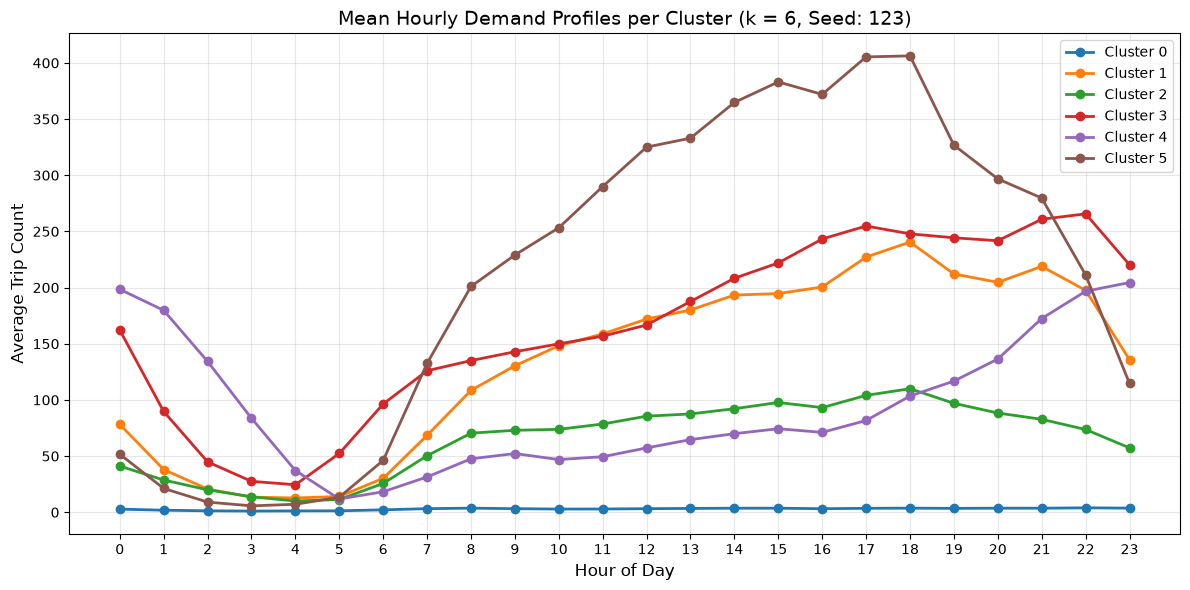

In [49]:
# Ensure labels are updated for your chosen optimal_k and random_state
profile_df["cluster"] = final_labels
cluster_profiles = profile_df.groupby("cluster").mean()

plt.figure(figsize=(12, 6))
for cluster_id in range(optimal_k):
  plt.plot(
      range(24),
      cluster_profiles.loc[cluster_id, range(24)],
      marker="o",
      linewidth=2,
      label=f"Cluster {cluster_id}",
  )

plt.title(
    f"Mean Hourly Demand Profiles per Cluster (k = {optimal_k},"
    f" Seed: {seed})",
    fontsize=14,
)
plt.xlabel("Hour of Day", fontsize=12)
plt.ylabel("Average Trip Count", fontsize=12)
plt.xticks(range(24))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the plot with both k and random seed in the filename
plt.savefig(
    f"../reports/figures/kmeans_cluster_profiles_k{optimal_k}_seed_{seed}.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

In [50]:
import pandas as pd

# Load the official NYC TLC taxi zone lookup file
# (Adjust the path if your CSV is stored in a subfolder like 'data/taxi_zone_lookup.csv')
lookup_df = pd.read_csv("../data/spatial/taxi_zone_lookup.csv")

# Ensure the ID column matches your dataframe's zone_id format (usually 'LocationID')
# Sometimes the column is named 'LocationID' in the official TLC dataset.

# 1. Extract zone metadata and merge with the lookup table for descriptive names
zone_meta = (
    train_df[["zone_id", "Borough", "service_zone"]]
    .drop_duplicates()
    .set_index("zone_id")
)

# Map the exact Zone names using LocationID as the key
zone_meta["Zone"] = lookup_df.set_index("LocationID")["Zone"]

# 2. Combine cluster labels with zone metadata and average hourly demand
cluster_summary_df = zone_meta.copy()
cluster_summary_df["cluster"] = profile_df["cluster"]
cluster_summary_df["avg_hourly_trips"] = profile_df[range(24)].mean(axis=1)

# 3. Print a structured breakdown of the zones in each cluster using DataFrame to_string()
for cluster_id in sorted(cluster_summary_df["cluster"].unique()):
  subset = cluster_summary_df[
      cluster_summary_df["cluster"] == cluster_id
  ].sort_values(by="avg_hourly_trips", ascending=False)

  print(f"{'='*60}")
  print(
      f"CLUSTER {cluster_id} | Total Zones: {len(subset)} | Mean Demand:"
      f" {subset['avg_hourly_trips'].mean():.1f} trips/hr"
  )
  print(f"Borough Breakdown: {subset['Borough'].value_counts().to_dict()}")
  print(f"{'-'*60}")

  # Print top 15 busiest zones using to_string() instead of display()
  print(subset[["Zone", "Borough", "service_zone", "avg_hourly_trips"]].head(15).to_string())
  print("\n")

CLUSTER 0 | Total Zones: 221 | Mean Demand: 2.9 trips/hr
Borough Breakdown: {'Queens': 67, 'Brooklyn': 61, 'Bronx': 43, 'Manhattan': 29, 'Staten Island': 20, 'EWR': 1}
------------------------------------------------------------
                             Zone    Borough service_zone  avg_hourly_trips
zone_id                                                                    
87       Financial District North  Manhattan  Yellow Zone         34.034305
13              Battery Park City  Manhattan  Yellow Zone         31.693296
166           Morningside Heights  Manhattan    Boro Zone         26.588816
125                     Hudson Sq  Manhattan  Yellow Zone         25.568452
261            World Trade Center  Manhattan  Yellow Zone         25.402569
41                 Central Harlem  Manhattan    Boro Zone         19.888001
74              East Harlem North  Manhattan    Boro Zone         18.210213
88       Financial District South  Manhattan  Yellow Zone         16.517074
70         